# 07 The operational model: accuracy by decision moment

Figures for `docs/operational_model.md`. The operational deliverable of findings 10.35 is one global CatBoost per
decision moment:
- 24 h and 3 h before the scheduled off-block;
- H1, 15 min before the last filed off-block;
- H0, at the off-block, a 2025-only comparison.

Every input exists at that moment (`docs/operational_features.md`).

**How the figures are read.**
- **Population and holdout:** the OP population (NM-matched departures with a target below one hour) of the Jan+Jul
  2025 holdout. Each model is fitted on the other ten months.
- **Deliverable rows:** the seed means (two seeds at 24 h and 3 h, three at H1). Their calibrated medians come from
  tables fitted on the 2025 month pairs only. At H1 the file ships rule M's median instead: a model fitted on the
  absolute error, clamped into the calibrated P10-P90 band (row `D-H1-MAE`).
- **Inputs:** `docs/operational_ladder.csv` and `docs/operational_ladder_calibration.csv`, both written by
  `lab/op_ladder_report.py`. No model is trained here.

Each figure's cell prints the numbers it draws.

In [1]:
import sys; sys.path.insert(0, ".")
import paper_style as ps; ps.setup()
from prc import paths
import pandas as pd, numpy as np, matplotlib.pyplot as plt

T = pd.read_csv(paths.ROOT / "docs" / "operational_ladder.csv")
CAL = pd.read_csv(paths.ROOT / "docs" / "operational_ladder_calibration.csv")
MOMENTS = [("D-24H", "24 h ahead"), ("D-3H", "3 h ahead"), ("D-H1", "H1\n(15 min)"),
           ("op_h0_r4_nodoy", "H0\n(push)")]
OP = T[(T["population"] == "OP") & (T["slice"] == "all")].set_index("row")
present = [(k, n) for k, n in MOMENTS if k in OP.index]
print("rows found:", [k for k, _ in present])

rows found: ['D-24H', 'D-3H', 'D-H1', 'op_h0_r4_nodoy']


## Accuracy against the distance to the movement

The closer the prediction to the movement, the more it knows: the weather in force, the traffic of the last hour,
NM's readings of the flights that just departed, and finally the push itself. The left panel shows the OP MAE of the
mean output, of the calibrated median and, at H1, of the median the file ships (rule M). The right panel shows the
share within ±2 min, the A-CDM manual's
(tentative) accuracy target for taxi times. The stand × runway table (B1), the airports' variable-taxi-time practice,
is the reference line.

     moment  mae_mean  w120_mean  mae_med  w120_med  mae_ship  w120_ship
 24 h ahead   218.186      0.401  215.380     0.426       NaN        NaN
  3 h ahead   214.524      0.402  211.603     0.427       NaN        NaN
H1 (15 min)   184.293      0.474  180.787     0.497   178.764      0.509
  H0 (push)   178.216      0.485      NaN       NaN       NaN        NaN
B1 stand x runway table: MAE 207.4 s, within 2 min 45.5 %


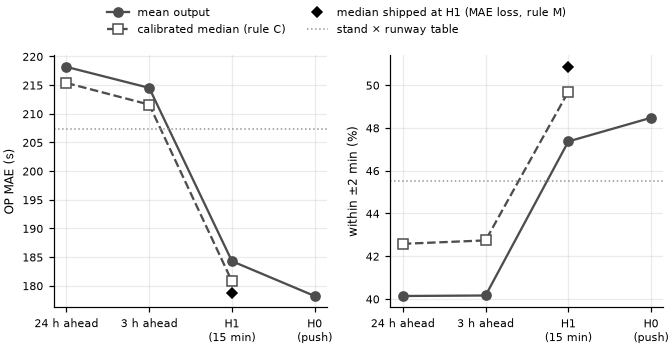

In [2]:
rows = []
for key, name in present:
    r = {"moment": name.replace("\n", " "), "mae_mean": OP.loc[key, "mae"], "w120_mean": OP.loc[key, "within_120"]}
    med = f"{key}-MED"
    if med in OP.index:
        r.update(mae_med=OP.loc[med, "mae"], w120_med=OP.loc[med, "within_120"])
    ship = f"{key}-MAE"
    if ship in OP.index:
        r.update(mae_ship=OP.loc[ship, "mae"], w120_ship=OP.loc[ship, "within_120"])
    rows.append(r)
H = pd.DataFrame(rows)
print(H.round(3).to_string(index=False))
b1 = OP.loc["B1"] if "B1" in OP.index else None
if b1 is not None:
    print(f"B1 stand x runway table: MAE {b1['mae']:.1f} s, within 2 min {100 * b1['within_120']:.1f} %")

fig, axes = plt.subplots(1, 2, figsize=(ps.WIDTH, 2.9))
x = np.arange(len(H))
for ax, (m, mm, ms, ylab, scale) in zip(axes, (("mae_mean", "mae_med", "mae_ship", "OP MAE (s)", 1.0),
                                               ("w120_mean", "w120_med", "w120_ship", "within ±2 min (%)", 100.0))):
    ax.plot(x, scale * H[m], "o-", color="#4D4D4D", label="mean output")
    if mm in H:
        ax.plot(x, scale * H[mm], "s--", color="#4D4D4D", mfc="white", label="calibrated median (rule C)")
    if ms in H:
        ax.plot(x, scale * H[ms], "D", color="#000000", ms=5, label="median shipped at H1 (MAE loss, rule M)")
    if b1 is not None:
        ax.axhline(scale * (b1["mae"] if m == "mae_mean" else b1["within_120"]), color="#969696", lw=1, ls=":",
                   label="stand × runway table")
    ax.set_xticks(x, [n for _, n in present], fontsize=7)
    ax.set_ylabel(ylab)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, fontsize=7, bbox_to_anchor=(0.5, 1.13), frameon=False)
fig.tight_layout()
ps.save(fig, "fig07_01_moments")
plt.show()

## The same per airport

Airports differ more than the moments do: their layout, runway system and traffic set the level. The figure shows the
OP MAE of each deliverable's mean output per airport.

row    D-24H   D-3H   D-H1  op_h0_r4_nodoy
level                                     
EHAM   221.7  218.4  142.0           139.9
LFPG   265.4  241.8  204.3           201.5
EGLL   262.3  268.0  245.0           240.6
EDDF   171.8  169.5  151.7           150.1
EDDM   203.5  190.2  159.4           156.5
LSZH   169.7  167.8  151.8           149.0
LTFM   243.3  241.9  204.2           194.1
LIRF   282.9  285.6  265.9           237.5
LEMD   162.7  163.4  148.6           144.1
LEBL   167.0  168.3  160.0           155.3


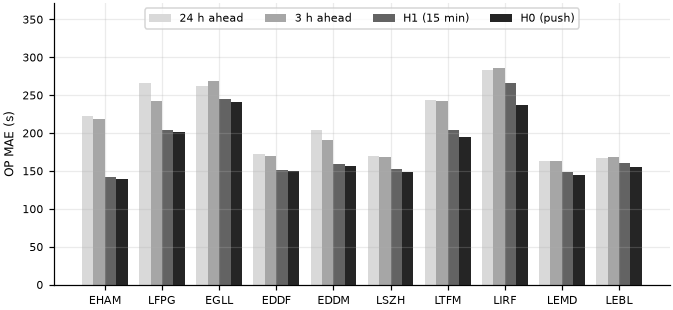

In [3]:
A = T[(T["population"] == "OP") & (T["slice"] == "apt")]
piv = A[A["row"].isin([k for k, _ in present])].pivot_table(index="level", columns="row", values="mae", aggfunc="first")
piv = piv[[k for k, _ in present if k in piv.columns]].reindex([a for a in ps.AIRPORTS if a in piv.index])
print(piv.round(1).to_string())
fig, ax = plt.subplots(figsize=(ps.WIDTH, 3.0))
w = 0.8 / max(len(piv.columns), 1)
greys = ["#D9D9D9", "#A6A6A6", "#636363", "#252525"]
for i, col in enumerate(piv.columns):
    ax.bar(np.arange(len(piv)) + (i - (len(piv.columns) - 1) / 2) * w, piv[col], width=w, color=greys[i % 4],
           label=dict(present)[col].replace("\n", " "))
ax.set_xticks(np.arange(len(piv)), [ps.label(a, "code") for a in piv.index])
ax.set_ylabel("OP MAE (s)")
ax.set_ylim(0, 1.3 * float(piv.max().max()))
ax.legend(ncol=4, loc="upper center", fontsize=7)
fig.tight_layout()
ps.save(fig, "fig07_02_airports")
plt.show()

## How honest the 80 % band is

The P10-P90 band comes from the residuals of the 2025 month pairs, not from the January and July holdout it is
checked on. The figure shows the share of OP departures inside the band per airport and deliverable. 80 % is the
nominal value, and rule C of findings 10.35 accepts 75-85 % overall.

deliverable  D-24H  D-3H  D-H1
apt                           
EHAM          76.1  74.7  77.2
LFPG          75.6  77.8  77.0
EGLL          78.7  77.6  76.8
EDDF          77.9  78.2  77.6
EDDM          74.7  75.6  76.8
LSZH          77.1  77.4  77.4
LTFM          80.1  80.1  78.8
LIRF          78.5  78.2  79.0
LEMD          78.8  78.0  78.6
LEBL          78.9  78.8  78.2
overall: {'D-24H': 77.7, 'D-3H': 77.7, 'D-H1': 77.7, 'D-H1-R4': 77.7}


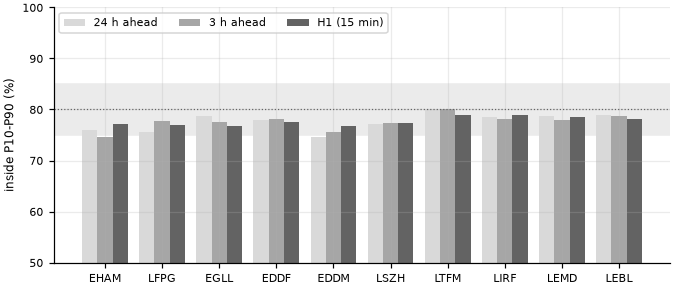

In [4]:
if CAL.empty:
    print("no calibration file rows: rule C was not evaluated")
else:
    piv = CAL[CAL["apt"] != "all"].pivot_table(index="apt", columns="deliverable", values="coverage", aggfunc="first")
    order = [k for k, _ in present if k in piv.columns]
    piv = piv[order].reindex([a for a in ps.AIRPORTS if a in piv.index])
    print((100 * piv).round(1).to_string())
    print("overall:", {r.deliverable: round(100 * r.coverage, 1) for r in CAL[CAL["apt"] == "all"].itertuples()})
    fig, ax = plt.subplots(figsize=(ps.WIDTH, 2.8))
    w = 0.8 / max(len(order), 1)
    greys = ["#D9D9D9", "#A6A6A6", "#636363"]
    for i, col in enumerate(order):
        ax.bar(np.arange(len(piv)) + (i - (len(order) - 1) / 2) * w, 100 * piv[col], width=w, color=greys[i % 3],
               label=dict(present)[col].replace("\n", " "))
    ax.axhspan(75, 85, color="#EBEBEB", zorder=0)
    ax.axhline(80, color="#636363", lw=0.8, ls=":")
    ax.set_ylim(50, 100)
    ax.set_xticks(np.arange(len(piv)), [ps.label(a, "code") for a in piv.index])
    ax.set_ylabel("inside P10-P90 (%)")
    ax.legend(ncol=3, loc="upper left", fontsize=7)
    fig.tight_layout()
    ps.save(fig, "fig07_03_band_coverage")